In [1]:
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

<Axes: xlabel='x', ylabel='y'>

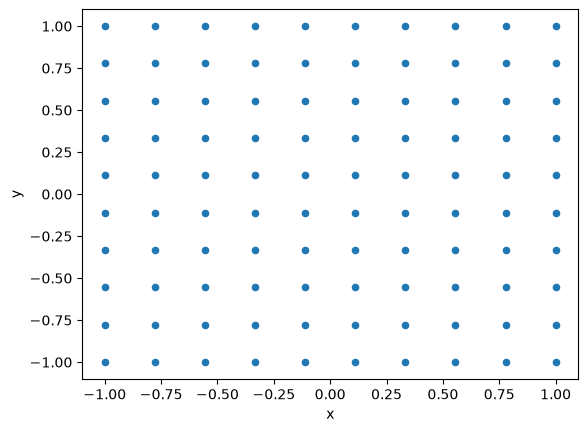

In [2]:
# data取得
def get_data():
    """make daa

    Returns:
        pd.DataFrame: 説明変数データ
    """
    n = 100
    xy = []
    for i in np.linspace(-1, 1, 10):
        for j in np.linspace(-1, 1, 10):
            xy.append([i, j])
    df = pd.DataFrame(xy, columns=["x", "y"])
    return df


g_df = get_data()

g_df.plot(x="x", y="y", kind="scatter")


ある領域で論文データがあったので加えるとする。

<Axes: xlabel='x', ylabel='y'>

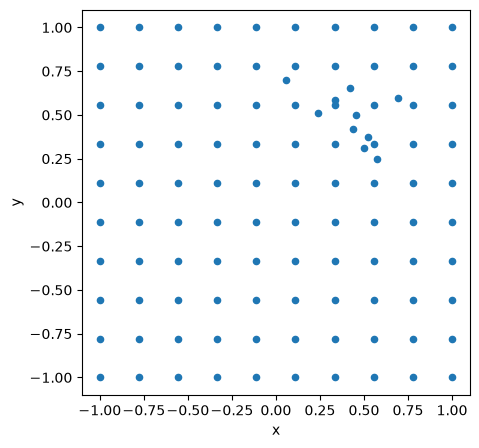

In [3]:
# data追加作成
def add_data(df):
    """観測データの追加を行う。

    Args:
        df (pd.DataFrame): 観測データ

    Returns:
        pd.DataFrame: 追加した観測データ
    """
    mean = [0.5, 0.5]
    cov = 0.2**2*np.array([[1, 0.0], [0.0, 1]])
    xy = np.random.multivariate_normal(mean=mean, cov=cov, size=10)
    df2 = pd.DataFrame(xy, columns=["x", "y"])
    dfraw = pd.concat([df, df2], axis=0).reset_index(drop=True)
    return dfraw
g_dfraw = add_data(g_df)
g_dfraw.plot(x="x", y="y", kind="scatter", figsize=(5, 5))


In [4]:
g_desriptor_labels = ["x", "y"]
g_Xraw = g_dfraw.loc[:, g_desriptor_labels].values

PCAによる変換を行う。

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def apply_pca(Xraw):
    """PCAを行う。

    Args:
        Xraw (np.ndarray): 説明変数

    Returns:
        np.ndarray: PCAで次元圧縮をした説明変数
    """
    # データプリプロセス
    scaler = StandardScaler()
    scaler.fit(Xraw)
    X = scaler.transform(Xraw)
    # データ解析
    pca = PCA(2)
    pca.fit(X)
    X_pca=pca.transform(X)
    return X_pca

g_X_pca = apply_pca(g_Xraw)

可視化を行う。

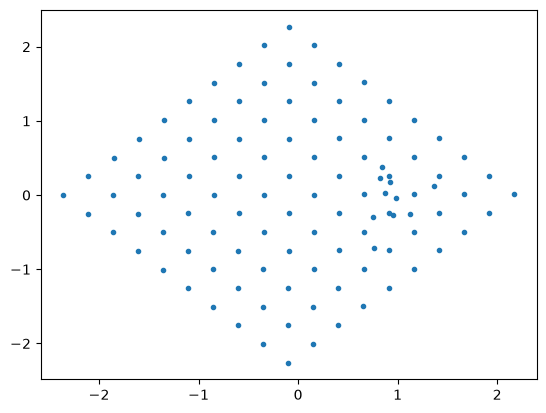

In [6]:
def show_X(X):
    fig, ax = plt.subplots()
    ax.plot(X[:,0], X[:,1], ".")
show_X(g_X_pca)

PCA変換した軸は意味がありそうな場合、単なるデータ取得の都合であることもあります。